# Lab 9 — MLP

**Phần thực hành — Nguyễn Đình Huy — 2474802010140**

Mỗi mục/bài là một cell code. Chạy từ trên xuống; hình được lưu vào `figures/`. Dùng `scripts/run_all.py` để lưu thêm nhật ký TXT vào `outputs/`.

## Mục 2 — Tự tính lan truyền tiến

Mot no-ron:
  z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
  a = sigmoid(z) = 0.8581

Mang giai XOR:
 x1  x2  h1  h2  y
 0   0   0   0   0
 0   1   1   0   1
 1   0   1   0   1
 1   1   2   1   0

Tinh ca bang mot lan: [0. 1. 1. 0.]


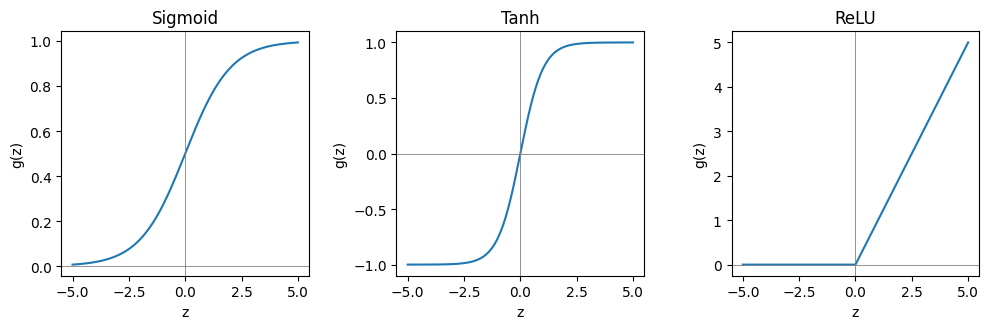

In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Mot no-ron:")
print(f"  z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]} + ({b}) = {z:.2f}")
print(f"  a = sigmoid(z) = {sigmoid(z):.4f}\n")
# Các cột của W1 là trọng số vào hai nơ-ron ẩn.
W1 = np.array([[1.0, 1.0], [1.0, 1.0]])
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print(" x1  x2  h1  h2  y")
for x in X:
    h = relu(x @ W1 + b1)
    y = h @ W2 + b2
    print(f" {x[0]:.0f}   {x[1]:.0f}   {h[0]:.0f}   {h[1]:.0f}   {y:.0f}")
print()
H = relu(X @ W1 + b1)
Y = H @ W2 + b2
print("Tinh ca bang mot lan:", Y)
z_plot = np.linspace(-5, 5, 300)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, ham, title in zip(axes, [sigmoid, np.tanh, relu], ["Sigmoid", "Tanh", "ReLU"]):
    ax.plot(z_plot, ham(z_plot))
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.axvline(0, color="gray", linewidth=0.6)
    ax.set(title=title, xlabel="z", ylabel="g(z)")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "ham_kich_hoat.png", dpi=150)
plt.show()


## Mục 3 — Một nơ-ron và một lớp ẩn trên XOR

Hoi quy logistic: 0.4500

So no-ron an  so tham so  tap hoc  tap kiem tra
     1            5      0.6533   0.6900
     2            9      0.6533   0.6900
     4           17      0.9033   0.9300


     8           33      0.9167   0.9100


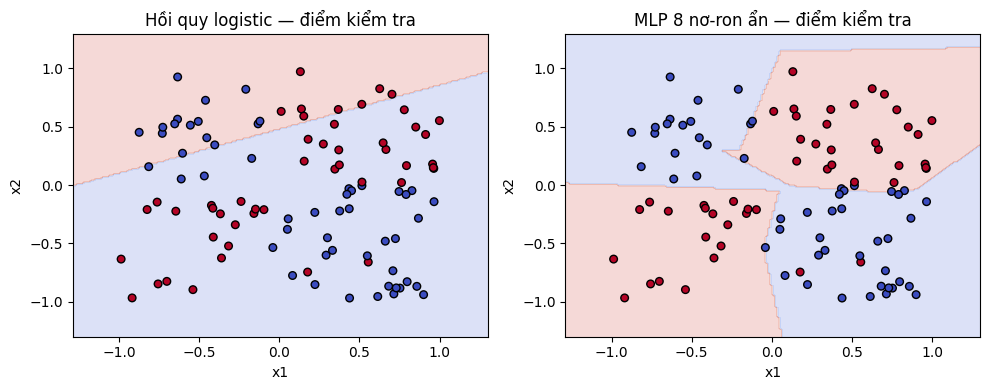

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
df = pd.read_csv(tep_du_lieu("xor.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}\n")
print("So no-ron an  so tham so  tap hoc  tap kiem tra")
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs", max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    so_ts = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f"    {so:2d}          {so_ts:3d}      {a_hoc:.4f}   {a_kt:.4f}")
# Lưới chỉ để vẽ ranh giới; không đưa vào huấn luyện.
xx, yy = np.meshgrid(np.linspace(X.x1.min() - .3, X.x1.max() + .3, 180),
                     np.linspace(X.x2.min() - .3, X.x2.max() + .3, 180))
luoi = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, model, title in zip(axes, [lr, mlp], ["Hồi quy logistic", "MLP 8 nơ-ron ẩn"]):
    ax.contourf(xx, yy, model.predict(luoi).reshape(xx.shape), alpha=.2, cmap="coolwarm")
    ax.scatter(X_te.x1, X_te.x2, c=y_te, cmap="coolwarm", edgecolors="black", s=30)
    ax.set(title=title + " — điểm kiểm tra", xlabel="x1", ylabel="x2")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "ranh_gioi_xor.png", dpi=150)
plt.show()


## Mục 4 — Độ lớn mạng và điều chuẩn

Ba mang               tap hoc  tap kiem tra
 (2,), alpha 1e-4   0.8444   0.8533


 (100,100), 1e-5    1.0000   0.7467


 (100,100), 1.0     0.8844   0.9067

alpha      kiem dinh cheo


 1e-05     0.7778


 0.001     0.7689


 0.1       0.7689


 1.0       0.8578


 3.0       0.8400


 10.0      0.8356


alpha tot nhat = 1.0, tap kiem tra 0.9067


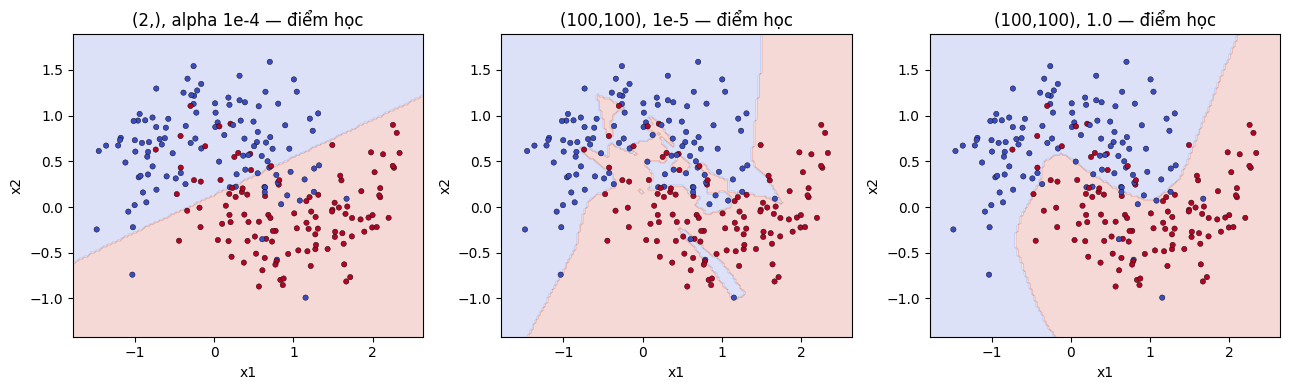

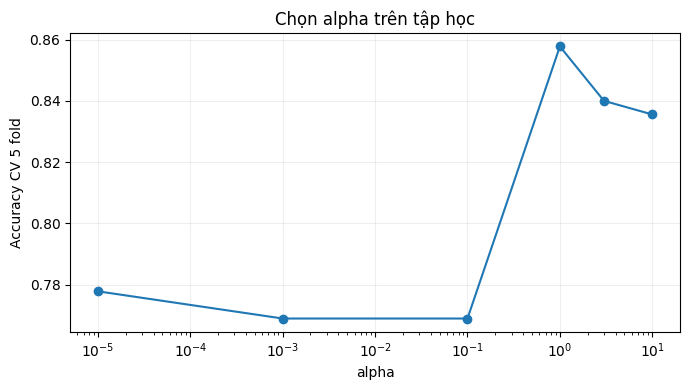

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

def mang(lop_an, alpha):
    return make_pipeline(StandardScaler(), MLPClassifier(
        hidden_layer_sizes=lop_an, alpha=alpha, solver="lbfgs", max_iter=20000, random_state=0))

print("Ba mang               tap hoc  tap kiem tra")
ba_mang = []
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                           ("(100,100), 1e-5", (100, 100), 1e-5),
                           ("(100,100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f" {ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}   {accuracy_score(y_te, m.predict(X_te)):.4f}")
    ba_mang.append((ten, m))
print()
# Chọn alpha chỉ từ các fold của tập học. Bảng trên minh họa theo đề.
print("alpha      kiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha), X_tr, y_tr, cv=5).mean()
    print(f" {alpha:<8}  {diem[alpha]:.4f}")
a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tot nhat = {a_tot}, tap kiem tra {accuracy_score(y_te, m.predict(X_te)):.4f}")
xx, yy = np.meshgrid(np.linspace(X.x1.min() - .3, X.x1.max() + .3, 150),
                     np.linspace(X.x2.min() - .3, X.x2.max() + .3, 150))
luoi = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (ten, model) in zip(axes, ba_mang):
    ax.contourf(xx, yy, model.predict(luoi).reshape(xx.shape), alpha=.2, cmap="coolwarm")
    ax.scatter(X_tr.x1, X_tr.x2, c=y_tr, cmap="coolwarm", s=15, edgecolors="black", linewidths=.3)
    ax.set(title=ten + " — điểm học", xlabel="x1", ylabel="x2")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "do_lon_va_dieu_chuan.png", dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(list(diem), list(diem.values()), "o-")
ax.set(xlabel="alpha", ylabel="Accuracy CV 5 fold", title="Chọn alpha trên tập học")
ax.grid(alpha=.2)
fig.tight_layout()
plt.savefig(thu_muc_hinh / "chon_alpha.png", dpi=150)
plt.show()


## Mục 5 — Mạng nơ-ron khi quên chuẩn hóa

Doan bua ca lop qua : 0.6000
Khong chuan hoa     : 0.4000
Co chuan hoa        : 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


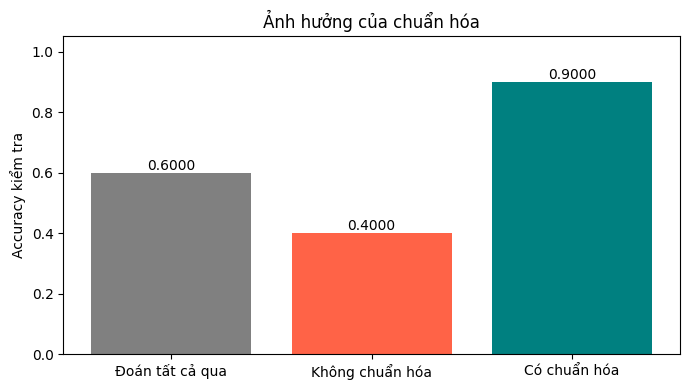

In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(tep_du_lieu("sinh_vien_mo_rong.csv"))
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000, random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(StandardScaler(), MLPClassifier(
    hidden_layer_sizes=(20,), max_iter=3000, random_state=0)).fit(X_tr, y_tr)
print(f"Doan bua ca lop qua : {y_te.mean():.4f}")
print(f"Khong chuan hoa     : {accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Co chuan hoa        : {accuracy_score(y_te, chuan.predict(X_te)):.4f}\n")
du = tho.predict(X_te)
print("Khong chuan hoa, so ban doan qua:", du.sum(), "tren", len(du))
fig, ax = plt.subplots(figsize=(7, 4))
scores = [y_te.mean(), accuracy_score(y_te, du), accuracy_score(y_te, chuan.predict(X_te))]
bars = ax.bar(["Đoán tất cả qua", "Không chuẩn hóa", "Có chuẩn hóa"], scores, color=["gray", "tomato", "teal"])
ax.bar_label(bars, fmt="%.4f")
ax.set(ylim=(0, 1.05), ylabel="Accuracy kiểm tra", title="Ảnh hưởng của chuẩn hóa")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "chuan_hoa_mlp.png", dpi=150)
plt.show()


## Mục 6 — Nhận dạng chữ số viết tay

Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
  anh   6: that la 9, doan la 3
  anh  61: that la 5, doan la 7
  anh  77: that la 2, doan la 1
  anh  85: that la 9, doan la 7
  anh 276: that la 8, doan la 2
  anh 428: that la 7, doan la 9
  anh 443: that la 4, doan la 7



Dung som sau 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711
KNN, k = 5             0.9867


SVM kernel RBF         0.9911


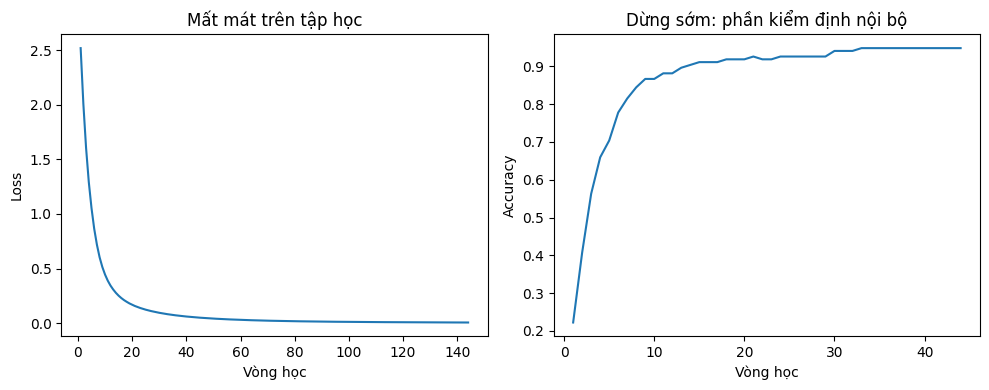

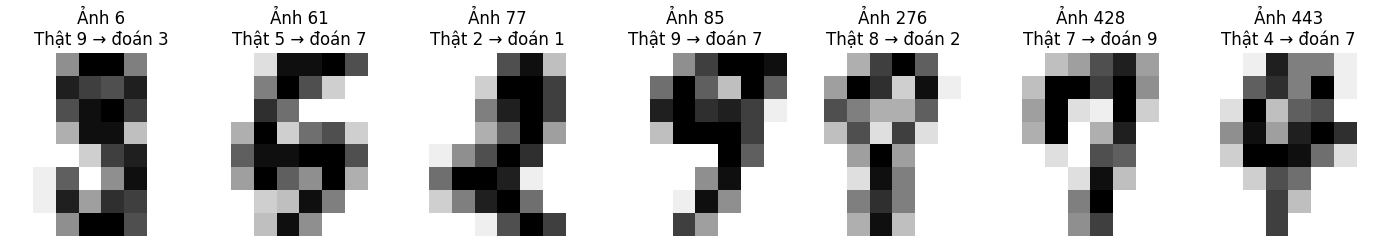

In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
mang = make_pipeline(StandardScaler(), MLPClassifier(
    hidden_layer_sizes=(100,), max_iter=1000, random_state=0)).fit(X_tr, y_tr)
mlp = mang[-1]
print("Kich thuoc cac ma tran trong so:", [w.shape for w in mlp.coefs_])
so_ts = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print("Tong so tham so:", so_ts)
print("So vong hoc:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f}, vong cuoi: {mm[-1]:.4f}\n")
du = mang.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du[i]}")
print()
dung_som = make_pipeline(StandardScaler(), MLPClassifier(
    hidden_layer_sizes=(100,), max_iter=1000, early_stopping=True, random_state=0)).fit(X_tr, y_tr)
print("Dung som sau", dung_som[-1].n_iter_, "vong, accuracy", f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}\n")
khac = {"Logistic co chuan hoa": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "KNN, k = 5": KNeighborsClassifier(), "SVM kernel RBF": SVC()}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(range(1, len(mm) + 1), mm)
axes[0].set(title="Mất mát trên tập học", xlabel="Vòng học", ylabel="Loss")
val = dung_som[-1].validation_scores_
axes[1].plot(range(1, len(val) + 1), val)
axes[1].set(title="Dừng sớm: phần kiểm định nội bộ", xlabel="Vòng học", ylabel="Accuracy")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "mat_mat_va_dung_som.png", dpi=150)
plt.show()
if len(sai):
    so_cot = min(7, len(sai))
    fig, axes = plt.subplots(int(np.ceil(len(sai) / so_cot)), so_cot, figsize=(2 * so_cot, 2.6 * int(np.ceil(len(sai) / so_cot))), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, sai):
        ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"Ảnh {i}\nThật {y_te[i]} → đoán {du[i]}")
    fig.tight_layout()
    plt.savefig(thu_muc_hinh / "chu_so_doan_sai.png", dpi=150)
    plt.show()
